# The L-shape, step by step

The L-shaped membrane is the standard corner benchmark: a reentrant corner of angle
$3\pi/2$. Every Dirichlet eigenfunction vanishes there, as on the rest of the boundary, but
generically only like $r^{2/3}\sin(2\theta/3)$, so its gradient blows up at the corner. The
exceptions are eigenfunctions whose local expansion has no fractional orders, such as
$\lambda_3 = 2\pi^2$ below.

This notebook walks the same workflow `lappy`'s notebooks use
(`lappy/jupyter_notebooks/lshape_convergence_test.ipynb`, `mps_diagnostics.ipynb`,
`mps demo.ipynb`), one step per section, in `chladni`:

| step | `lappy` | `chladni` |
|---|---|---|
| 1. domain | `geometry.L_shape()` | `geometry.L_shape()` |
| 2. basis | `FourierBesselBasis.from_domain(dom, [n,0,0,0,0,0])` | `FourierBessel.at_corner(corner, n, domain=dom)` |
| 3. collocation | `dom.bdry_pts(pts_per_seg)`, `dom.int_pts(...)` | `dom.bdry_quad(n)`, `dom.interior_pts(n, rng=)` |
| 4. normalization | `NormalizedBasis(basis, (bdry, int))` | inside: scaled columns in `helmholtz`, `equilibrate` in `mps` |
| 5. solver | `MPSEigensolver(basis, bdry, int)` | `MPSEigensolver(dom, basis=, bdry_quad=, int_pts=)` |
| 6. eyeball the tension | `solver.plot_tensions(faber_krahn, weyl_est, n)` | `solver.tension(grid)` over `weyl_window` |
| 7. one eigenvalue by hand | `opt.golden_search(solver.sigma, a, b)` | `minimize_scalar(solver.tension, ...)` |
| 8. convergence in $n$ | the `lshape_eig1(n_basis)` loop | the same loop |
| 9. all eigenvalues, certified | -- | `solver.search_interval(a, b)` |
| 10. eigenfunctions | `mps.nullspace_coef` | `solver.eigenfunctions(level)` |

**How to use it.** Several cells are preceded by a *Predict* prompt. Write your answer down
before running the cell. Each section ends with **Read the code** pointers.

**What `chladni` does not do yet:** choose the basis. There is no basis planner, so steps 2-3
are by hand, exactly as in `lappy`'s notebooks (`TODO.md` section 3).

Every quantitative claim is asserted inline; `tests/test_examples.py` executes this notebook.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar

from chladni import asymp, bounds
from chladni.geometry import L_shape
from chladni.helmholtz import CornerModes, FourierBessel, PlaneWave, PrecisionWarning
from chladni.mps import MPSEigensolver, equilibrate, lam_to_k, weyl_window
from chladni.plotting import field_grid, plot_diagnostic, plot_domain
from chladni.reference import L_shape_eigs

plt.rcParams.update({"figure.dpi": 100, "figure.constrained_layout.use": True, "font.size": 9})

TRUTH = np.asarray(L_shape_eigs(12), dtype=float)       # chladni.reference: a 14-digit table
print(f"reference table, {L_shape_eigs.digits:.0f} digits:")
print(np.array2string(TRUTH, precision=10))

reference table, 14 digits:
[ 9.639723844  15.1972519265 19.7392088022 29.5214811141 31.9126359571
 41.4745098902 44.9484877814 49.3480220054 49.3480220054 56.7096098874
 65.3765357098 71.0577556485]


## 1. The domain and its one singular corner

`L_shape()` is the $2\times2$ square with the upper-right unit square removed: area 3, the
reentrant vertex at the origin. `geometry` records each corner's interior angle $\omega$ and
boundary conditions, and classifies the angle; it never treats $\pi/\omega$ as an exponent.
Whether a corner is **singular** -- whether the eigenfunctions' local orders
$(l + \text{offset})\,\pi/\omega$ are not all integers -- needs the offset that the boundary
conditions set, so `helmholtz` answers it: `CornerModes.from_corner(c).is_singular`.

Geometry's own predicate, `Corner.is_reflection_closed`, asks only whether $\omega = \pi/m$.
With one boundary condition on both edges the two answers agree, as they do on every corner
here. They part at a boundary-condition junction: a straight edge that switches from Dirichlet
to Neumann is reflection-closed ($\omega = \pi$) but singular (orders $l + 1/2$). The rule that
reserves the word *singular* for `helmholtz` is in `docs/conventions.md`.

In `lappy` you choose which corners get Fourier-Bessel terms by the orders list
`[n, 0, 0, 0, 0, 0]`; here the corner object is chosen directly.

area 3, perimeter 8, diameter 2.8284

 vertex   omega/pi   pi/omega   reflection-closed   singular
 +0+0j     1.50     0.6667         False        True
 +0+1j     0.50     2.0000          True        False
 -1+1j     0.50     2.0000          True        False
 -1-1j     0.50     2.0000          True        False
 +1-1j     0.50     2.0000          True        False
 +1+0j     0.50     2.0000          True        False


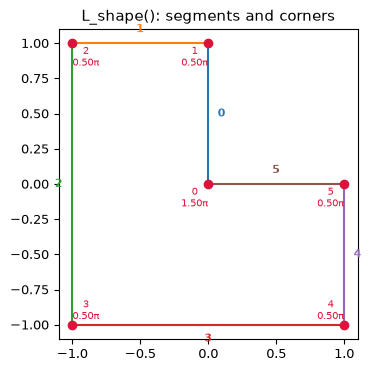

In [2]:
dom = L_shape()
print(f"area {dom.area:g}, perimeter {dom.perimeter:g}, diameter {dom.diameter:.4f}\n")
print(" vertex   omega/pi   pi/omega   reflection-closed   singular")
for c in dom.corners:
    print(f" {c.z.real:+.0f}{c.z.imag:+.0f}j    {c.omega / np.pi:5.2f}     {np.pi / c.omega:6.4f}    "
          f"{str(c.is_reflection_closed):>10s}        {CornerModes.from_corner(c).is_singular}")

singular = [c for c in dom.corners if CornerModes.from_corner(c).is_singular]
corner = singular[0]
assert len(singular) == 1 and corner.z == 0 and np.isclose(corner.omega, 1.5 * np.pi)

fig, ax = plt.subplots(figsize=(3.6, 3.6))
plot_diagnostic(dom, ax=ax)
ax.set_title("L_shape(): segments and corners")
plt.show()

**Read the code:** `geometry/library.py` (`L_shape`), `geometry/domain.py` (`Domain.corners`),
the `Corner` record in `geometry/boundary.py`.

## 2. The basis

`FourierBessel.at_corner` builds $J_{\nu_j}(kr)\sin(\nu_j\theta)$, $\nu_j = 2j/3$, from the
corner record: the orders, sine against cosine (from the boundary conditions on the two
edges), and the branch cut all come from `corner`. Each column satisfies the Dirichlet
condition on both edges at the corner exactly.

**Pass `domain=`.** It sets the radius the columns are scaled by to the farthest the basis
will be evaluated over the domain, rather than the corner's own clearance (the fallback,
correct only for evaluation near the corner). Exercise 4 in section 11 shows what the
difference does.

In [3]:
N_FB = 80
fb = FourierBessel.at_corner(corner, n=N_FB, domain=dom)
print(f"{len(fb)} columns; first orders {np.round(fb.orders[:5], 4)}")
print(f"scaling radius {fb.radius:.4f}: the farthest point of the domain from the corner "
      f"(clearance {corner.clearance:.4f})")
assert np.allclose(fb.orders[:3], [2 / 3, 4 / 3, 2])
assert np.isclose(fb.radius, np.sqrt(2))

80 columns; first orders [0.6667 1.3333 2.     2.6667 3.3333]
scaling radius 1.4142: the farthest point of the domain from the corner (clearance 1.0000)


**Read the code:** `helmholtz/fourier_bessel.py` (`FourierBessel.at_corner`),
`helmholtz/corners.py` (`CornerModes`), `helmholtz/_bessel.py` (Bessel values returned as
`S * exp(sigma)`, so high orders at small `k r` do not flush to zero).

## 3. Collocation points

The `CLAUDE.md` rule of thumb: about 3x as many boundary points as basis terms, and as many
interior points as terms. `bdry_quad(n)` splits `n` over the segments in proportion to
length and puts Gauss-Legendre nodes on each segment, so every point comes with a weight,
normal, tangent and boundary condition. `interior_pts(n, rng=)` samples uniformly by
rejection, from a seeded generator. The solver would build both from `n_bdry=` and `n_int=`;
they are built here so they can be looked at.

240 boundary nodes; weights sum to 8.000000000000 (perimeter 8)
80 interior points


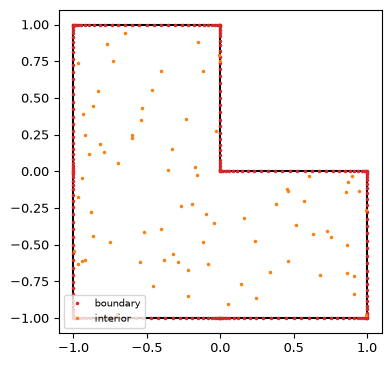

In [4]:
quad = dom.bdry_quad(3 * N_FB)
ipts = dom.interior_pts(N_FB, rng=np.random.default_rng(0))
print(f"{len(quad)} boundary nodes; weights sum to {quad.wts.sum():.12f} (perimeter {dom.perimeter:g})")
print(f"{len(ipts)} interior points")
assert abs(quad.wts.sum() - dom.perimeter) < 1e-12

fig, ax = plt.subplots(figsize=(3.8, 3.8))
plot_domain(dom, ax=ax, fill=False)
ax.plot(quad.pts.real, quad.pts.imag, ".", ms=3, color="C3", label="boundary")
ax.plot(ipts.real, ipts.imag, ".", ms=3, color="C1", label="interior")
ax.set_aspect("equal")
ax.legend(loc="lower left", fontsize=7)
plt.show()

Unlike `mps demo.ipynb`'s Betcke-Trefethen setup, there are points on the two edges at the
reentrant corner (segments 0 and 5). The corner family vanishes on those edges identically,
so those rows of the boundary block are zero to rounding -- the next section's matrices show
it -- and cost only space.

**Read the code:** `geometry/domain.py` (`bdry_quad`, `interior_pts`),
`geometry/quadrature.py` (`Quadrature`).

## 4. Normalization

In `lappy` you wrap the basis in `NormalizedBasis` on the point sets. In `chladni` there is no
separate step; the job is split across two layers, and both happen automatically:

* `helmholtz` returns **scaled columns**: each column divided by a known scale (here from
  the radius in section 2), with the scale's logarithm kept separately. This keeps the entries
  accurate.
* `mps` **equilibrates**: every column is divided by its 2-norm over the *stacked* boundary and
  interior points. Scaling the two blocks separately would change the ratio the tension
  measures.

Below, the raw collocation matrices at $\lambda_1$ and their column norms before and after.

> **Predict.** How far apart are the largest and smallest column norms before equilibration?

A_B (240, 80), A_I (80, 80)
largest |A_B| entry on the corner's own edges: 1.7e-15, elsewhere: 1.1e+00
column norms before: 1.3e+00 .. 1.1e+01   after: 1.000000 .. 1.000000


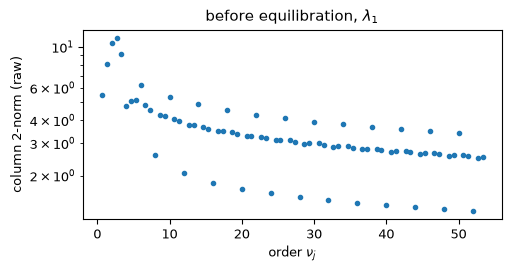

In [5]:
lam1 = TRUTH[0]
s_fixed = MPSEigensolver(dom, basis=fb, bdry_quad=quad, int_pts=ipts, prec=1e-12)
A_B, A_I = s_fixed.pencil.matrices(lam1)                 # raw, before equilibration
B, I, log_norms = equilibrate(A_B, A_I)
raw = np.linalg.norm(np.vstack([A_B, A_I]), axis=0)
after = np.linalg.norm(np.vstack([B, I]), axis=0)
print(f"A_B {A_B.shape}, A_I {A_I.shape}")
at_corner_edges = np.isin(quad.seg_idx, [0, 5])
print(f"largest |A_B| entry on the corner's own edges: {np.abs(A_B[at_corner_edges]).max():.1e}, "
      f"elsewhere: {np.abs(A_B[~at_corner_edges]).max():.1e}")
assert np.abs(A_B[at_corner_edges]).max() < 1e-12
print(f"column norms before: {raw.min():.1e} .. {raw.max():.1e}   after: {after.min():.6f} .. {after.max():.6f}")
assert np.allclose(after, 1.0)

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.semilogy(fb.orders, raw, ".")
ax.set(xlabel=r"order $\nu_j$", ylabel="column 2-norm (raw)", title=r"before equilibration, $\lambda_1$")
plt.show()

The raw norms span only about a decade, because the `helmholtz` scaling has already taken out
the Bessel functions' enormous range in $\nu$ and $kr$ (it is kept in log scales, which add).
Equilibration evens out what is left. Neither step needs the caller.

**Read the code:** `mps/pencil.py` (`assemble`, `equilibrate`, `MPSPencil.matrices`),
`docs/conventions.md` (who owns which scaling).

## 5. The solver

`MPSEigensolver(dom, basis=, bdry_quad=, int_pts=)` takes the domain too, unlike `lappy`'s,
because that is where Weyl windows, boundary conditions and the certified bound come from. It
also takes `prec`, and `prec` sets the **regularization**. Two are worth comparing:

* a Tikhonov penalty (`reg="tikhonov_qr"`) with `tau` proportional to `prec`, which puts a floor
  of about `tau` under the tension;
* a rank-truncation threshold at `sqrt(prec * eps)`, whose floor is the basis's own. This is the
  default (`reg="auto"`) at every `prec` since 2026-10-10; the penalty was the default at
  `prec >= 1e-8` before that, and lost to the threshold on `douse` shapes
  (`notes/regularization_1e10.md`).

This tour asks for the penalty at `prec=1e-8` by name, so the two floors can be compared.

The `n_bdry=`/`n_int=` form builds exactly the point sets from section 3, which the assert
checks.

In [6]:
solvers = {p: MPSEigensolver(dom, basis=fb, n_bdry=3 * N_FB, n_int=N_FB, prec=p, reg=reg)
           for p, reg in ((1e-8, "tikhonov_qr"), (1e-12, "auto"))}
for p, s in solvers.items():
    print(f"prec={p:.0e}: reg={s.reg!r}, {s.n_cols} columns, {s.n_bdry} boundary + {s.n_int} interior points")
assert solvers[1e-8].reg == "tikhonov_qr" and solvers[1e-12].reg == "svd"
assert s_fixed.tension(lam1) == solvers[1e-12].tension(lam1)   # same points, same pencil

prec=1e-08: reg='tikhonov_qr', 80 columns, 240 boundary + 80 interior points
prec=1e-12: reg='svd', 80 columns, 240 boundary + 80 interior points


**Read the code:** `mps/solver.py` (`MPSEigensolver.__init__`), `mps/pencil.py` (`MPSPencil`,
the `reg == "auto"` branch), `mps/_regularize.py`.

## 6. Eyeball the tension

`lappy`'s `plot_tensions(faber_krahn, weyl_est(k), n)` has its counterpart in
`weyl_window(dom, k)`: Faber-Krahn (padded) below, the inverted Weyl law above.

> **Predict.** How many minima in the window for the first 7 eigenvalues? How deep is the
> well at $\lambda_1$ at each `prec`?

window for 7 eigenvalues: [6.050, 54.910]   (Faber-Krahn 6.056)


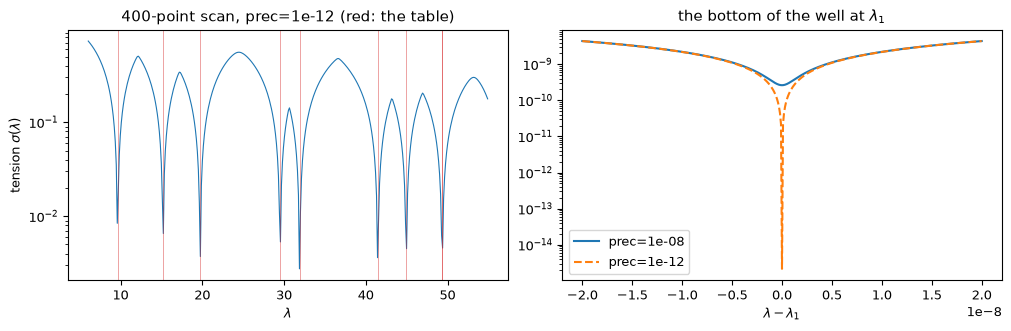

well floor: 2.6e-10 at prec=1e-8,  2.2e-15 at prec=1e-12


In [7]:
a, b = weyl_window(dom, 7)
print(f"window for 7 eigenvalues: [{a:.3f}, {b:.3f}]   (Faber-Krahn {bounds.faber_krahn(dom):.3f})")
grid = np.linspace(a, b, 400)
scan = solvers[1e-12].tension(grid)

zoom = lam1 + np.linspace(-2e-8, 2e-8, 401)       # the floor region is ~1e-9 wide
wells = {p: s.tension(zoom) for p, s in solvers.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
ax1.semilogy(grid, scan, lw=0.8)
for x in TRUTH[TRUTH <= b]:
    ax1.axvline(x, color="C3", lw=0.5, alpha=0.6)
ax1.set(xlabel=r"$\lambda$", ylabel=r"tension $\sigma(\lambda)$",
        title="400-point scan, prec=1e-12 (red: the table)")
for (p, w), ls in zip(wells.items(), ["-", "--"]):
    ax2.semilogy(zoom - lam1, w, ls, label=f"prec={p:.0e}")
ax2.set(xlabel=r"$\lambda - \lambda_1$", title=r"the bottom of the well at $\lambda_1$")
ax2.legend()
plt.show()

floor8, floor12 = (s.tension(lam1) for s in solvers.values())   # at the table's value
print(f"well floor: {floor8:.1e} at prec=1e-8,  {floor12:.1e} at prec=1e-12")
assert floor8 > 1e3 * floor12

The minima are easy to see by eye, but the scan never touches their bottoms: the wells are far
narrower than the grid spacing. Reading eigenvalues off a scan is not possible, and narrow
wells are exactly how `lappy` dropped modes in `douse` runs
(`docs/design/douse_failure_cases.md`, case T1.1).

At `prec=1e-8` the penalty floors the well, by design. The location is still found to within
`prec`, and section 9's certified bound reports what was really reached.

## 7. One eigenvalue by hand

The `lappy` notebooks' next move: bracket a minimum by eye and minimize over the bracket.

> **Predict.** `scipy`'s bounded Brent, asked for `xatol = 1e-13 * lam_1`: how close does it
> get?

In [8]:
s12 = solvers[1e-12]
res = minimize_scalar(s12.tension, bounds=(9.0, 10.5), method="bounded",
                      options={"xatol": 1e-13 * lam1})
err_brent = abs(res.x - lam1) / lam1
print(f"bounded Brent: lam_1 = {res.x:.14f}, relative error {err_brent:.1e}, {res.nfev} evaluations")
assert err_brent > 1e-10          # it stops early, whatever xatol says


def golden(f, a, b, tol):
    # Plain golden-section search, as in lappy's opt.golden_search: no parabolic steps and
    # no built-in relative tolerance, so it shrinks the bracket until b - a < tol.
    g = (np.sqrt(5) - 1) / 2
    c, d = b - g * (b - a), a + g * (b - a)
    fc, fd, n = f(c), f(d), 2
    while b - a > tol:
        if fc < fd:
            b, d, fd = d, c, fc
            c = b - g * (b - a)
            fc = f(c)
        else:
            a, c, fc = c, d, fd
            d = a + g * (b - a)
            fd = f(d)
        n += 1
    return 0.5 * (a + b), n


x_gold, n_gold = golden(s12.tension, 9.0, 10.5, 1e-13 * lam1)
err_gold = abs(x_gold - lam1) / lam1
print(f"golden section: lam_1 = {x_gold:.14f}, relative error {err_gold:.1e}, {n_gold} evaluations")
assert err_gold < 1e-12

bounded Brent: lam_1 = 9.63972380186970, relative error 4.4e-09, 22 evaluations


golden section: lam_1 = 9.63972384402187, relative error 7.6e-15, 61 evaluations


Bounded Brent stops near 1e-8 relative, because `scipy` adds `sqrt(eps) * |x|`, about
`1.5e-8 * |x|`, to `xatol` internally, so no setting of `xatol` gets past it. Golden section
has no such term and goes as far as the well allows. Silent limits like this one are a reason
the refine stage in section 9 is `chladni`'s own code with `prec`-derived tolerances rather
than a library call.

And both worked only because you chose the bracket by looking. The search in section 9 has to find
every bracket itself and decide how many eigenvalues each holds.

## 8. Convergence in the number of terms

The `lshape_convergence_test.ipynb` experiment: $\lambda_1$ and its tension as the number of
corner terms grows, with plane waves for contrast.

> **Predict.** Exponential convergence in $n$, or algebraic? Roughly how many terms for 1e-12?

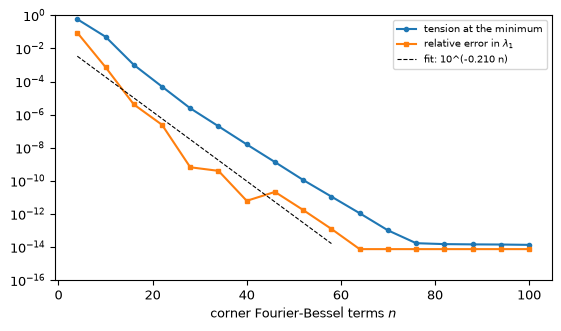

error falls about 0.21 decades per term (exponential)
52 plane waves: lam_1 error 3.8e-02, tension 3.4e-01
the same plane waves at lam_3 = 2 pi^2: tension 2.3e-15


In [9]:
def lam1_with(basis):
    s = MPSEigensolver(dom, basis=basis, n_bdry=3 * len(basis), n_int=len(basis), prec=1e-12)
    x, _ = golden(s.tension, 9.0, 10.5, 1e-13 * lam1)
    return x, s.tension(x)

ns = np.arange(4, 101, 6)
conv = np.array([lam1_with(FourierBessel.at_corner(corner, n=n, domain=dom)) for n in ns])
relerr = np.abs(conv[:, 0] - lam1) / lam1
tens = conv[:, 1]

fit = relerr > 1e-13
slope, icpt = np.polyfit(ns[fit], np.log10(relerr[fit]), 1)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.semilogy(ns, tens, "o-", ms=3, label="tension at the minimum")
ax.semilogy(ns, relerr, "s-", ms=3, label=r"relative error in $\lambda_1$")
ax.semilogy(ns[fit], 10 ** (slope * ns[fit] + icpt), "k--", lw=0.8,
            label=f"fit: 10^({slope:.3f} n)")
ax.set(xlabel="corner Fourier-Bessel terms $n$", ylim=(1e-16, 1))
ax.legend(fontsize=7)
plt.show()

n_pw = int(1.3 * PlaneWave.n_useful(np.sqrt(b) * dom.diameter))
x_pw, t_pw = lam1_with(PlaneWave.uniform(n_pw, radius=dom.diameter))
print(f"error falls about {-slope:.2f} decades per term (exponential)")
print(f"{n_pw} plane waves: lam_1 error {abs(x_pw - lam1) / lam1:.1e}, tension {t_pw:.1e}")
s_pw = MPSEigensolver(dom, basis=PlaneWave.uniform(n_pw, radius=dom.diameter),
                      n_bdry=3 * n_pw, n_int=n_pw, prec=1e-12)
t_pw3 = s_pw.tension(TRUTH[2])
print(f"the same plane waves at lam_3 = 2 pi^2: tension {t_pw3:.1e}")
assert slope < -0.1 and relerr[-1] < 1e-12
assert abs(x_pw - lam1) / lam1 > 1e-3 and t_pw3 < 1e-8

Exponential in $n$, and the tension tracks the error, which is what lets the tension stand in
for an error estimate. The plane waves sized for this window cannot represent $r^{2/3}$: they
get $\lambda_1$ to barely one digit. At $\lambda_3 = 2\pi^2$ the same plane waves are excellent,
because that eigenfunction is $\sin(\pi x)\sin(\pi y)$ on each of the three unit squares, with
no $r^{2/3}$ term at all. That is `CLAUDE.md`'s point that the basis is "*by far* the most important
consideration".

## 9. Every eigenvalue in a window, with a certified bound

`search_interval(a, b)` does what sections 6-7 did by hand, for every well: **bracket**,
**refine** to `prec`, decide the **multiplicity**, assemble. Then it attaches a
**Moler-Payne bound** to each Dirichlet level. The bound needs only the candidate function:
its boundary residual against its $L^2(\Omega)$ norm, with the norm from boundary data through
the Rellich identity on a quadrature rule graded into the corner.

Each `Level` has two **absolute** error bars: `delta_res` (from the well's floor) and
`mp_bound` (some true eigenvalue lies within it). `bound` is the tighter. The table has 14
digits, so errors much below `1e-14 * lam` cannot be judged against it.

> **Predict.** At `prec=1e-8`, are the actual errors near 1e-8 relative or much smaller?
> Which bar is tighter at each `prec`?

In [10]:
def report(res):
    print(f"{'lam':>18s} {'mult':>4s} {'|error|':>9s} {'delta_res':>9s} {'mp_bound':>9s} {'bound':>9s}")
    errs = []
    for L in res.levels:
        errs.append(np.min(np.abs(TRUTH - L.lam)))
        print(f"{L.lam:18.13f} {L.mult:4d} {errs[-1]:9.1e} {L.delta_res:9.1e} {L.mp_bound:9.1e} {L.bound:9.1e}")
    d = res.diagnostics
    print(f"attained precision {d.attained_prec:.1e} (relative); declined: {d.declined}")
    return np.array(errs)

results = {}
for p, s in solvers.items():
    t0 = time.perf_counter()
    results[p] = s.search_interval(5.0, 45.0)
    print(f"\n--- prec={p:.0e}, [5, 45], {time.perf_counter() - t0:.1f} s")
    errs = report(results[p])
    lams = np.array([L.lam for L in results[p].levels])
    bars = np.array([L.bound for L in results[p].levels])
    assert len(lams) == 7 and all(L.mult == 1 for L in results[p].levels)
    assert np.all(errs <= bars + 1e-14 * lams)           # every bar holds against the table
    assert np.all(errs <= p * lams)                      # and every value meets the request


--- prec=1e-08, [5, 45], 1.2 s
               lam mult   |error| delta_res  mp_bound     bound
   9.6397238448055    1   7.8e-10   2.9e-09   2.5e-09   2.5e-09
  15.1972519255648    1   8.9e-10   3.7e-09   3.6e-09   3.6e-09
  19.7392088038605    1   1.7e-09   5.7e-09   5.8e-09   5.7e-09
  29.5214811140365    1   1.1e-10   5.1e-09   5.6e-10   5.6e-10
  31.9126359723648    1   1.5e-08   3.1e-08   9.8e-08   3.1e-08
  41.4745098898235    1   3.9e-10   5.8e-09   3.0e-09   3.0e-09
  44.9484877799307    1   1.4e-09   7.0e-09   9.6e-09   7.0e-09
attained precision 9.7e-10 (relative); declined: False



--- prec=1e-12, [5, 45], 1.3 s
               lam mult   |error| delta_res  mp_bound     bound
   9.6397238440220    1   1.8e-14   5.1e-14   1.3e-13   5.1e-14
  15.1972519264540    1   2.9e-13   6.5e-13   1.5e-12   6.5e-13
  19.7392088021795    1   7.6e-13   1.5e-12   2.8e-12   1.5e-12
  29.5214811141449    1   5.7e-14   7.4e-14   1.5e-12   7.4e-14
  31.9126359571379    1   1.3e-13   2.3e-13   2.3e-12   2.3e-13
  41.4745098902149    1   2.1e-14   2.9e-13   4.9e-12   2.9e-13
  44.9484877813509    1   3.0e-13   5.7e-13   6.3e-12   5.7e-13
attained precision 7.8e-14 (relative); declined: False


* **Seven levels, all simple**, as in the table. The count is an answer, not a byproduct.
* **At `prec=1e-8` the errors are about 4e-12 to 5e-10 relative**, comfortably inside the
  request, and every bar covers its error within a factor of about 2-8. The two bars are
  comparable here; Moler-Payne is the tighter on four of the seven. (On rectangles it was two
  to three orders tighter than `delta_res`, `notes/moler_payne_vs_tension.md`; that did not
  carry over to this case.)
* **At `prec=1e-12` the errors are about 2e-15 to 4e-14 relative**, at the table's last
  digits, and `delta_res` is the tighter bar on every level, because under the threshold the
  floor is the basis's own.

**A warning you may see.** The search can emit a `PrecisionWarning` from `FourierBessel` while
assembling the pencil, saying the columns reach only about 1e-7 relative accuracy against the
family's own `prec` (1e-8, the default, since `at_corner` was not given `prec=`). It does not
fire on every run, because it depends on which `lam` the search evaluates. Building the family
with `prec=1e-12` instead makes it fire on most evaluations, and the eigenvalues come out the
same either way, to about 4e-14. So this per-entry warning does not track eigenvalue accuracy
here. Why it does not is an open question worth reading `helmholtz/_core.py`
(`_check_accuracy`) and `Sampling.accuracy` for.

An independent count check: Weyl's law with corner terms predicts the count with $O(1)$ error.
It can show a mode is missing, never prove that none is.

In [11]:
n_found = sum(L.mult for L in results[1e-12].levels)
weyl = asymp.weyl_count_poly(45.0, dom) - asymp.weyl_count_poly(5.0, dom)
print(f"found {n_found} in [5, 45]; three-term Weyl with corner terms predicts {weyl:.2f}")
assert abs(n_found - weyl) < 1.0

spec = s12.solve_interval(5.0, 45.0)        # the method-agnostic answer
print(spec)
assert np.array_equal(spec.mult, np.ones(7, dtype=int))

found 7 in [5, 45]; three-term Weyl with corner terms predicts 6.70


/Users/hringer/projects/python/chladni/src/chladni/helmholtz/_core.py:195: PrecisionWarning: FourierBessel can deliver about 1e-7 relative accuracy on these points, short of the requested prec=1e-08. The limit is the Bessel kernel's own scale, not the point set: see Sampling.accuracy(k) for the per-column bound.
  return self.values(k, cols)


Spectrum(lam=array([ 9.63972384, 15.19725193, 19.7392088 , 29.52148111, 31.91263596,
       41.47450989, 44.94848778]), mult=array([1, 1, 1, 1, 1, 1, 1]), bound=array([5.05527185e-14, 6.53699317e-13, 1.53182211e-12, 7.44793358e-14,
       2.26391455e-13, 2.93595720e-13, 5.72942900e-13]), prec=1e-12, declined=False, reason='')


`solve_interval` narrows the MPS-specific result to the `Spectrum` every eigensolver
contracts for: levels, multiplicities, absolute bars. A failed search or an uncertain count
raises; a precision shortfall warns. So an empty `Spectrum` can only mean "none here".

**Read the code:** `mps/solver.py` (`search_interval`, `certify_levels`, `solve_interval`),
`mps/search.py` (`solve`, `Level`), `mps/bracket.py` (`bracket_interval`), `mps/refine.py`
(`refine`), `mps/multiplicity.py` (`multiplicity`), `integrals/plan.py` (`integral_quad`),
`integrals/certify.py` (`moler_payne`), `eigensolver.py` (`Spectrum`). Specs:
`docs/design/search.md`, `docs/design/boundary_integrals.md`.

## 10. Eigenfunctions

`lappy`'s notebooks take a null vector with `mps.nullspace_coef` and look at it.
`eigenfunctions(level)` returns coefficients in the basis's own coordinates, already
L2-orthonormal: the Gram matrix comes from the Rellich identity on the corner-graded boundary
rule, then Löwdin orthonormalization. No interior quadrature is used, so integrating $u^2$ on
a plain grid below is an independent check.

Evaluating the corner family at points across the whole domain reaches about 1e-7 relative,
and `FourierBessel` warns. That is plenty for a picture and a grid integral, so the warning is
silenced in this cell.

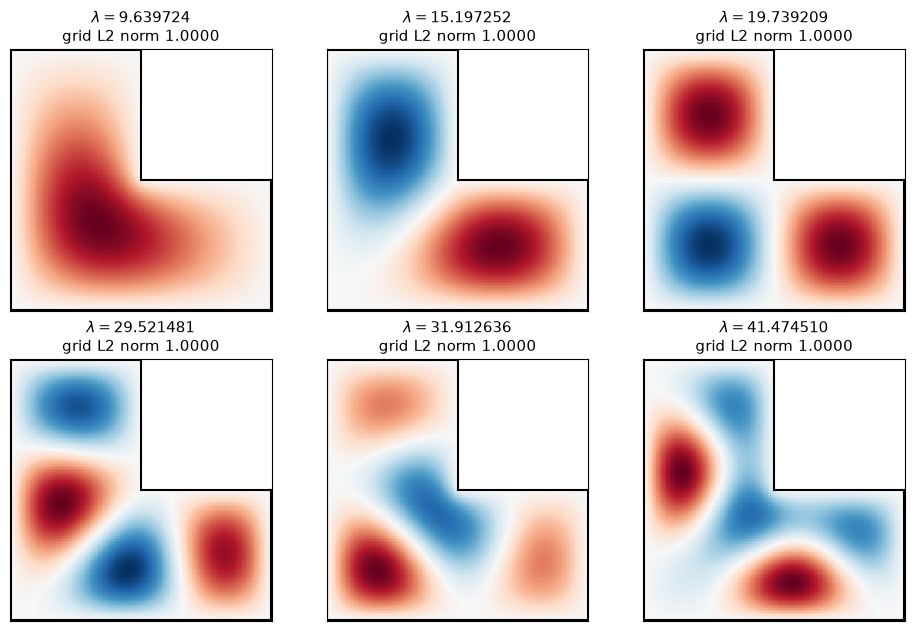

In [12]:
res12 = results[1e-12]
X, Y, mask = field_grid(dom, 160)
z = (X + 1j * Y)[mask]
h = (X[0, 1] - X[0, 0]) * (Y[1, 0] - Y[0, 0])

fig, axes = plt.subplots(2, 3, figsize=(9.5, 6.2))
for ax, L in zip(axes.flat, res12.levels[:6]):
    ef = s12.eigenfunctions(L)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", PrecisionWarning)
        u = (fb.values(lam_to_k(L.lam), z) @ ef.coef)[:, 0].real
    grid_norm = np.sum(u ** 2) * h
    assert ef.orthonormal and ef.gram_residual < 1e-10
    assert abs(grid_norm - 1) < 2e-2                      # a crude grid, so a loose tolerance
    U = np.full(X.shape, np.nan)
    U[mask] = u
    m = np.nanmax(np.abs(U))
    ax.pcolormesh(X, Y, U, cmap="RdBu_r", vmin=-m, vmax=m, shading="auto")
    plot_domain(dom, ax=ax, fill=False)
    ax.set_aspect("equal")
    ax.set_title(rf"$\lambda = {L.lam:.6f}$" + "\n" + f"grid L2 norm {grid_norm:.4f}")
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Modes 1, 2, 4 and 5 bend sharply around the corner; mode 3 is the three-tile $2\pi^2$ mode.

The coefficients themselves, as `lshape_convergence_test.ipynb` plotted them, and the
singularity: along the bisector into the domain, $u_1 \approx c\,r^{2/3}$, so the log-log slope
should approach $2/3$ at the corner.

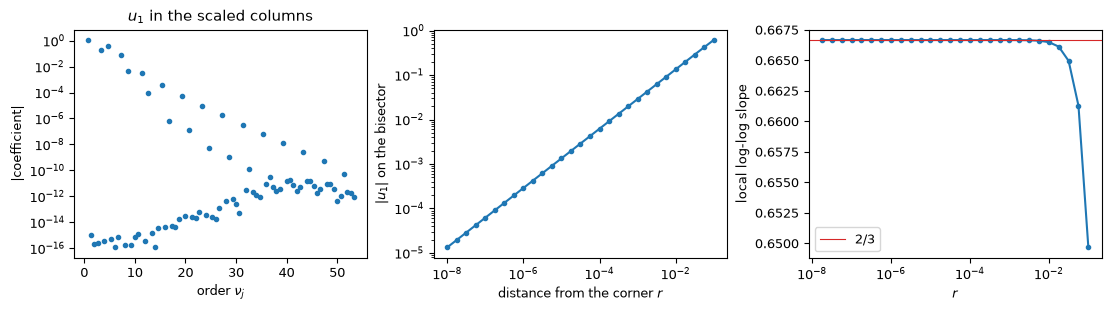

slope nearest the corner: 0.6666666667


In [13]:
L1 = res12.levels[0]
ef1 = s12.eigenfunctions(L1)
r = np.logspace(-8, -1, 29)
ray = r * np.exp(-0.75j * np.pi)            # the bisector of the 270-degree corner
u_ray = np.abs((fb.values(lam_to_k(L1.lam), ray) @ ef1.coef)[:, 0])
slope_r = np.diff(np.log(u_ray)) / np.diff(np.log(r))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(11, 3))
ax1.semilogy(fb.orders, np.abs(ef1.coef[:, 0]), ".")
ax1.set(xlabel=r"order $\nu_j$", ylabel="|coefficient|", title=r"$u_1$ in the scaled columns")
ax2.loglog(r, u_ray, ".-")
ax2.set(xlabel="distance from the corner $r$", ylabel=r"$|u_1|$ on the bisector")
ax3.semilogx(r[1:], slope_r, ".-")
ax3.axhline(2 / 3, color="C3", lw=0.8, label="2/3")
ax3.set(xlabel="$r$", ylabel="local log-log slope")
ax3.legend()
plt.show()

print(f"slope nearest the corner: {slope_r[0]:.10f}")
assert abs(slope_r[0] - 2 / 3) < 1e-6

The slope is $2/3$ to many digits near the corner and drifts as the $r^{4/3}$ term takes over.
A plane-wave basis has to approximate this; the corner family has it as its first column.

**Read the code:** `mps/solver.py` (`eigenfunctions`, `Eigenfunctions`),
`mps/pencil.py` (`family_coef`), `integrals/cauchy.py` (`cauchy_data`),
`integrals/identities.py` (`gram`, `lowdin`).

## 11. Things to try

Each takes an edit or two above. Predict first.

1. **Starve the basis.** Set `N_FB = 30` and rerun from section 2 at `prec=1e-12`. Does the
   search drop a level, report a shortfall, or decline? Do the bars still hold?
2. **Ask for too much.** `prec=1e-14` with 80 terms. What does `solve_interval` do, and is
   `attained_prec` honest?
3. **Mix the bases.** `fb + PlaneWave.uniform(40, radius=dom.diameter)`. Better or worse than
   `fb` alone, and why?
4. **Forget `domain=`.** `FourierBessel.at_corner(corner, n=80)` scales by the clearance, 1,
   instead of $\sqrt2$. What happens to section 4's column norms, and to the tension floor?
5. **Go higher.** Search $[45, 75]$: the table's 8th and 9th entries are the double
   eigenvalue $5\pi^2$. One level of multiplicity 2? Do 80 terms still suffice?
6. **Neumann.** `L_shape(bc="neu")` needs the cosine family at the corner, which `at_corner`
   derives from the boundary conditions. Moler-Payne does not apply; what does each level's
   `bound_reason` say?

The design records for each layer are in `docs/design/` (`geometry.md`,
`particular_solutions.md`, `mps.md`, `search.md`, `boundary_integrals.md`). Read them for the
*why*; the code is the authority on the *what*.